<div align="center">

<h1>Buzz in Social Media</h1>

<h3>Analyse du dataset UCI <em>Buzz in Social Media</em></h3>

<p><b>Côme Rossary</b> &nbsp;&middot;&nbsp; <b>Batiste Fancellu</b></p>

<p>4 novembre 2026</p>

</div>

---

## 1. Objectif

L'objectif de ce devoir et de ce notebook est d'extraire le maximum d'information pertinente du dataset « Buzz in Social Media », créé par François Kawala, Ahlame Douzal, Eric Gaussier et Eustache Diemert (Université Joseph Fourier / BestofMedia Group) et mis en ligne sur le dépôt UCI en mai 2013.

Ce dataset suit l'activité autour de sujets sur deux réseaux sociaux différents :
- Twitter ;
- Tom's Hardware, un forum consacré aux nouvelles technologies et ayant des dynamiques plus conservatrices.

Avant d'aller plus loin, importons ce dataset.

In [1]:
import os

# Sur Google Colab : téléchargement du dossier du projet depuis Google Drive.
# En local : on suppose être déjà dans le dossier du projet.
if os.path.exists("/content"):
    if not os.path.exists("/content/projet"):
        !pip install -q gdown
        !gdown -q --folder 1oaoxufMxfSdoyX4hrLdCGesuG3NUDZ57 -O /content/projet
    %cd /content/projet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

## Sommaire

1. Objectif
2. Présentation des données
   - 2.1 Ce que nous apprend le fichier .names
3. État des données
4. Prédire le buzz
   - 4.1 La cible
   - 4.2 Les attributs
   - 4.3 Une seule série : trois modèles naïfs
   - 4.4 Plusieurs séries : corrélations entre indicateurs
   - 4.5 Toutes les séries : une méthode à base d'arbres
   - 4.6 D'autres méthodes de régression
5. Comparatif des modèles de prédiction entre Twitter et Tom's Hardware
6. Reconnaître le réseau à la dynamique d'un sujet : classification
7. Conclusion : les modèles de buzz de chacun

## 2. Présentation des données

Le dataset contient un dossier par réseau social, `Twitter` et `TomsHardware`, avec deux fichiers chacun :

- `*.data` : les données, au format CSV sans en-tête, une ligne par sujet ;
- `*.names` : la documentation du fichier `.data`, au format texte habituel des datasets UCI.

### 2.1 Ce que nous apprend le fichier `.names`

Pour les deux datasets, chaque ligne correspond à un sujet (un exemple). Les attributs sont des indicateurs d'activité mesurés à plusieurs pas de temps consécutifs. La dernière colonne est la valeur à prédire.

**Dossier `Twitter`** : chaque ligne est composée de 77 attributs, soit 11 indicateurs × 7 pas de temps (t = 0 à 6), dans cet ordre :

| Colonnes | Indicateur | Signification |
|---|---|---|
| 0 à 6 | NCD, *Number of Created Discussions* | nombre de discussions créées sur le sujet |
| 7 à 13 | AI, *Author Increase* | nombre de nouveaux auteurs sur le sujet |
| 14 à 20 | AS(NA), *Attention Level (authors)* | part des auteurs du réseau qui écrivent sur le sujet |
| 21 à 27 | BL, *Burstiness Level* | NCD / NAD : part des discussions actives qui viennent d'être créées |
| 28 à 34 | NAC, *Number of Atomic Containers* | nombre de contributions (tweets) sur le sujet |
| 35 à 41 | AS(NAC), *Attention Level (contributions)* | part des contributions du réseau qui concernent le sujet |
| 42 à 48 | CS, *Contribution Sparseness* | dispersion des contributions entre les discussions du sujet |
| 49 à 55 | AT, *Author Interaction* | nombre moyen d'auteurs par discussion |
| 56 à 62 | NA, *Number of Authors* | nombre d'auteurs actifs sur le sujet |
| 63 à 69 | ADL, *Average Discussion Length* | longueur moyenne d'une discussion |
| 70 à 76 | NAD, *Number of Active Discussions* | nombre de discussions actives sur le sujet |
| 77 | cible | nombre moyen de discussions actives (NAD) dans les semaines suivantes |

**Dossier `TomsHardware`** : chaque ligne est composée de 96 attributs, soit 12 indicateurs × 8 pas de temps (t = 0 à 7). Ce sont les mêmes indicateurs dans un ordre différent, plus un indicateur propre au forum :

| Colonnes | Indicateur |
|---|---|
| 0 à 7 | NCD |
| 8 à 15 | BL |
| 16 à 23 | NAD |
| 24 à 31 | AI |
| 32 à 39 | NAC, ici le nombre de messages postés |
| 40 à 47 | ND, *Number of Displays* : nombre d'affichages des discussions du sujet |
| 48 à 55 | CS |
| 56 à 63 | AT |
| 64 à 71 | NA |
| 72 à 79 | ADL |
| 80 à 87 | AS(NA) |
| 88 à 95 | AS(NAC) |
| 96 | cible : nombre moyen d'affichages (ND) dans les semaines suivantes |

## 3. État des données

Avant toute analyse, vérifions que les deux fichiers sont propres :

1. le nombre de colonnes est celui annoncé par le `.names` : 77 + 1 pour Twitter, 96 + 1 pour Tom's Hardware ;
2. toutes les colonnes sont numériques ;
3. aucune valeur manquante ni infinie ;
4. aucune valeur négative : ce sont des comptes, des ratios et des moyennes ;
5. les indicateurs de comptage (NCD, AI, NAC, NA, NAD, ND) ne contiennent que des entiers ;
6. les indicateurs définis sur [0, 1] (AS(NA), AS(NAC), BL, CS) restent dans cet intervalle ;
7. aucune colonne constante, qui n'apporterait aucune information ;
8. nombre de lignes dupliquées et de lignes entièrement nulles, à connaître avant de modéliser.

In [2]:
from pathlib import Path

# Indicateurs dans l'ordre des colonnes de chaque fichier .data, et nombre de pas de temps (cf. .names).
DATASETS = {
    "Twitter": {
        "n_steps": 7,
        "indicateurs": ["NCD", "AI", "AS(NA)", "BL", "NAC", "AS(NAC)", "CS", "AT", "NA", "ADL", "NAD"],
    },
    "TomsHardware": {
        "n_steps": 8,
        "indicateurs": ["NCD", "BL", "NAD", "AI", "NAC", "ND", "CS", "AT", "NA", "ADL", "AS(NA)", "AS(NAC)"],
    },
}
COMPTAGES = {"NCD", "AI", "NAC", "NA", "NAD", "ND"}   # valeurs entières attendues
RATIOS = {"AS(NA)", "AS(NAC)", "BL", "CS"}            # valeurs dans [0, 1] attendues


def charger(nom):
    """Charge <nom>.data (cherché depuis le dossier courant) et nomme les colonnes X_t ; la dernière est 'cible'."""
    fichiers = list(Path(".").rglob(f"{nom}.data"))
    assert fichiers, f"{nom}.data introuvable depuis {Path.cwd()}"
    spec = DATASETS[nom]
    colonnes = [f"{ind}_{t}" for ind in spec["indicateurs"] for t in range(spec["n_steps"])] + ["cible"]
    df = pd.read_csv(fichiers[0], header=None)
    df.columns = colonnes[: df.shape[1]] if df.shape[1] <= len(colonnes) else range(df.shape[1])
    return df


def verifier(nom, df):
    spec = DATASETS[nom]
    num = df.select_dtypes("number")
    comptages = [c for c in num.columns if str(c).split("_")[0] in COMPTAGES]
    ratios = [c for c in num.columns if str(c).split("_")[0] in RATIOS]
    return {
        "lignes": len(df),
        "colonnes": df.shape[1],
        "colonnes attendues": len(spec["indicateurs"]) * spec["n_steps"] + 1,
        "colonnes non numériques": df.shape[1] - num.shape[1],
        "valeurs manquantes": int(df.isna().sum().sum()),
        "valeurs infinies": int(np.isinf(num).sum().sum()),
        "valeurs négatives": int((num < 0).sum().sum()),
        "comptages non entiers": int((df[comptages] % 1 != 0).sum().sum()),
        "ratios hors [0, 1]": int(((df[ratios] < 0) | (df[ratios] > 1)).sum().sum()),
        "colonnes constantes": int((df.nunique() <= 1).sum()),
        "lignes dupliquées": int(df.duplicated().sum()),
        "lignes entièrement nulles": int((num.drop(columns="cible", errors="ignore") == 0).all(axis=1).sum()),
    }


data = {nom: charger(nom) for nom in DATASETS}
pd.DataFrame({nom: verifier(nom, df) for nom, df in data.items()})

,Twitter,TomsHardware
lignes,583250,28179
colonnes,78,97
colonnes attendues,78,97
colonnes non numériques,0,0
valeurs manquantes,0,0
valeurs infinies,0,0
valeurs négatives,0,0
comptages non entiers,0,0
"ratios hors [0, 1]",0,0
colonnes constantes,0,0


Tout est conforme. On remarque seulement un nombre notable de lignes dupliquées : 6 016 sur Twitter, soit 1,0 % du dataset, et 25 sur Tom's Hardware, soit 0,1 %. Il s'agit probablement de sujets avec très peu d'interactions (un tweet ou une page vue à un ou deux pas de temps), dont le motif d'activité se répète à l'identique d'un sujet à l'autre. Pour l'instant, nous n'en tiendrons pas compte.

## 4. Prédire le buzz

Le premier objectif naturel, et celui pour lequel les auteurs ont construit le dataset, est de prédire le buzz, c'est-à-dire la dernière colonne, à partir des colonnes précédentes, qui décrivent l'activité observée sur la fenêtre. C'est un problème de régression, à traiter séparément pour chaque dataset puisque la cible n'est pas la même : nombre moyen de discussions actives pour Twitter, nombre moyen d'affichages pour Tom's Hardware.

Les auteurs précisent dans le `.names` que leurs résultats sont corrects mais limités par le déséquilibre du dataset (beaucoup de sujets sans buzz, quelques sujets énormes). Ils suggèrent de normaliser les attributs et d'ajouter comme attributs supplémentaires les différences entre pas de temps consécutifs.

Au-delà du score obtenu, prédire le buzz sur chaque réseau est un moyen d'en comprendre le fonctionnement : quels indicateurs comptent, à quel horizon, et en quoi les deux réseaux diffèrent.

### 4.1 La cible

Les auteurs préviennent que le dataset est déséquilibré (grande majorité de sujets sans buzz). On commence donc par observer ce déséquilibre sur la cible, pour décider s'il faut changer d'échelle la cible.

In [3]:
pd.DataFrame({
    "médiane": {nom: df["cible"].median() for nom, df in data.items()},
    "max": {nom: df["cible"].max() for nom, df in data.items()},
    "part de sujets avec cible = 0": {nom: df["cible"].eq(0).mean() for nom, df in data.items()},
    "part du buzz total détenue par 1 % des sujets": {
        nom: df["cible"].nlargest(len(df) // 100).sum() / df["cible"].sum() for nom, df in data.items()
    },
}).T.round(3)

,Twitter,TomsHardware
médiane,25.500,359.000
max,75724.500,265916.500
part de sujets avec cible = 0,0.033,0.004
part du buzz total détenue par 1 % des sujets,0.224,0.302


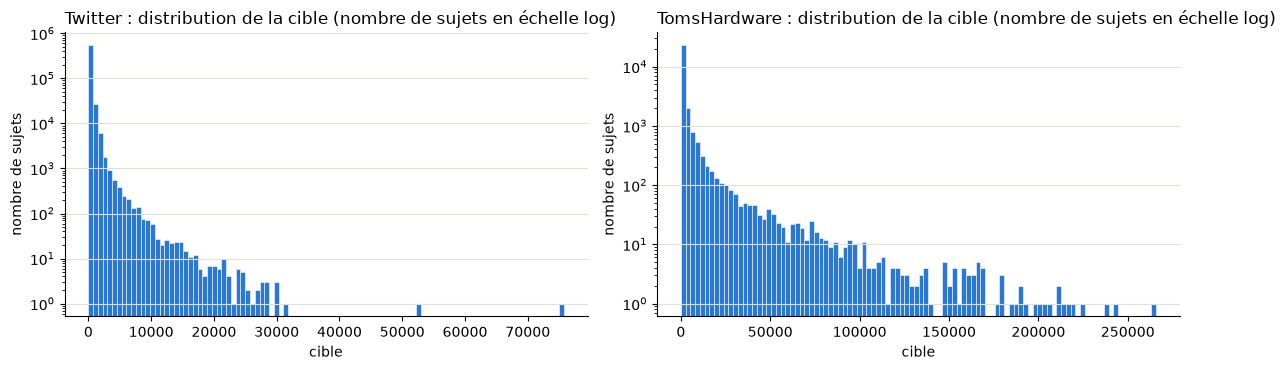

In [4]:
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e1e0d9", "axes.titlelocation": "left",
})
BLEU = "#2a78d6"

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (nom, df) in zip(axes, data.items()):
    ax.hist(df["cible"], bins=100, color=BLEU, edgecolor="white", linewidth=0.4)
    ax.set_yscale("log")
    ax.set_title(f"{nom} : distribution de la cible (nombre de sujets en échelle log)")
    ax.set_xlabel("cible")
    ax.set_ylabel("nombre de sujets")
fig.tight_layout()
plt.show()

Le déséquilibre est net. Sur Twitter, la moitié des sujets ont une cible inférieure à 26 et le maximum dépasse 75 000 ; sur Tom's Hardware, médiane 359 et maximum 266 000. L'échelle log de l'axe vertical est nécessaire pour voir autre chose qu'une barre à zéro : presque tous les sujets sont dans la première barre, et la queue de distribution s'étire sur cinq ordres de grandeur avec une poignée de sujets.

C'est un problème pour une régression classique. L'erreur quadratique donne à un sujet à 75 000 prédit à 50 000 le même poids que des milliers de petits sujets prédits à 50 au lieu de 25. Le modèle ajusterait donc une poignée de sujets énormes et ignorerait tous les autres, et son score ne refléterait que ces quelques sujets. De plus, une erreur de 25 000 n'a pas le même sens pour un sujet à 100 et pour un sujet à 75 000 : ce qui compte pour un buzz, c'est l'ordre de grandeur.

On propose donc de travailler sur log(1 + cible) plutôt que sur la cible brute, pour trois raisons :

- une erreur sur le log est une erreur relative : se tromper d'un facteur 2 pèse pareil pour un sujet à 10 et pour un sujet à 10 000, ce qui est la bonne notion d'erreur pour un buzz ;
- la transformation compresse la queue de distribution : les sujets énormes ne dominent plus l'ajustement, et la cible devient à peu près en cloche, ce qui convient bien aux modèles linéaires et aux moindres carrés ;
- le « + 1 » permet de garder les sujets à cible nulle, puisque log(0) n'existe pas, et envoie 0 sur 0.

Vérifions l'effet sur les deux datasets.

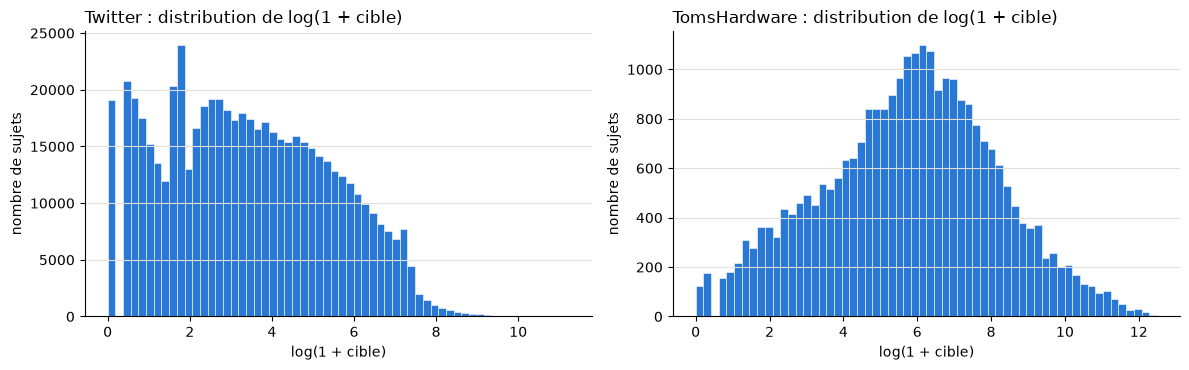

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (nom, df) in zip(axes, data.items()):
    ax.hist(np.log1p(df["cible"]), bins=60, color=BLEU, edgecolor="white", linewidth=0.4)
    ax.set_title(f"{nom} : distribution de log(1 + cible)")
    ax.set_xlabel("log(1 + cible)")
    ax.set_ylabel("nombre de sujets")
fig.tight_layout()
plt.show()

Les deux distributions tiennent maintenant sur une échelle de 0 à 12 sans queue extrême, et celle de Tom's Hardware est presque gaussienne. C'est sur cette cible transformée qu'on fera la régression.

### 4.2 Les attributs

Les attributs décrivent la même activité que la cible, on s'attend donc au même déséquilibre. Chaque indicateur est mesuré à 7 ou 8 pas de temps : ses colonnes doivent être regardées, et plus tard transformées, de la même manière quel que soit le pas, sinon une même quantité aurait des échelles différentes selon la colonne. On regarde donc chaque indicateur avec tous ses pas de temps ensemble.

In [6]:
def bilan_attributs(nom, df):
    spec = DATASETS[nom]
    lignes = {}
    for ind in spec["indicateurs"]:
        v = df[[f"{ind}_{t}" for t in range(spec["n_steps"])]].to_numpy().ravel()
        lignes[ind] = {"médiane": np.median(v), "max": v.max(), "part de valeurs à 0": (v == 0).mean()}
    return pd.DataFrame(lignes).T.round(3).rename_axis(nom)


for nom, df in data.items():
    display(bilan_attributs(nom, df))

,médiane,max,part de valeurs à 0
Twitter,,,
NCD,24.0,79079.000,0.065
AI,14.0,63147.000,0.096
AS(NA),0.0,0.095,0.065
BL,1.0,1.000,0.065
NAC,26.0,79136.000,0.065
AS(NAC),0.0,0.046,0.087
CS,1.0,1.000,0.065
AT,1.0,283.000,0.065
NA,22.0,72159.000,0.065


,médiane,max,part de valeurs à 0
TomsHardware,,,
NCD,0.0,182.000,0.760
BL,0.0,1.000,0.760
NAD,0.0,217.000,0.618
AI,0.0,169.000,0.667
NAC,0.0,1966.000,0.618
ND,326.0,330561.000,0.011
CS,0.0,1.000,0.618
AT,0.0,107.000,0.618
NA,0.0,322.000,0.618


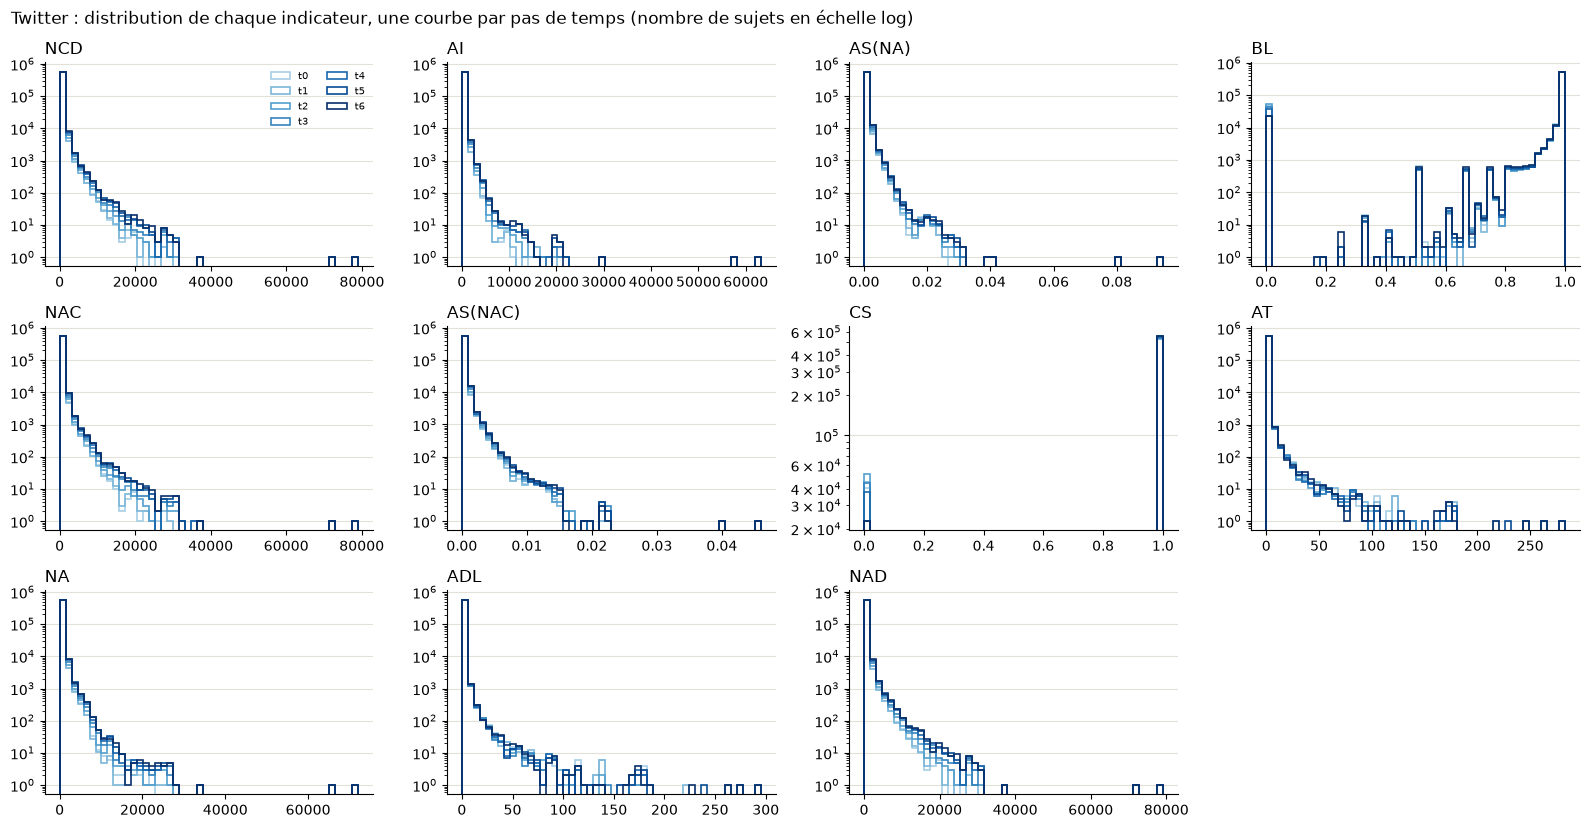

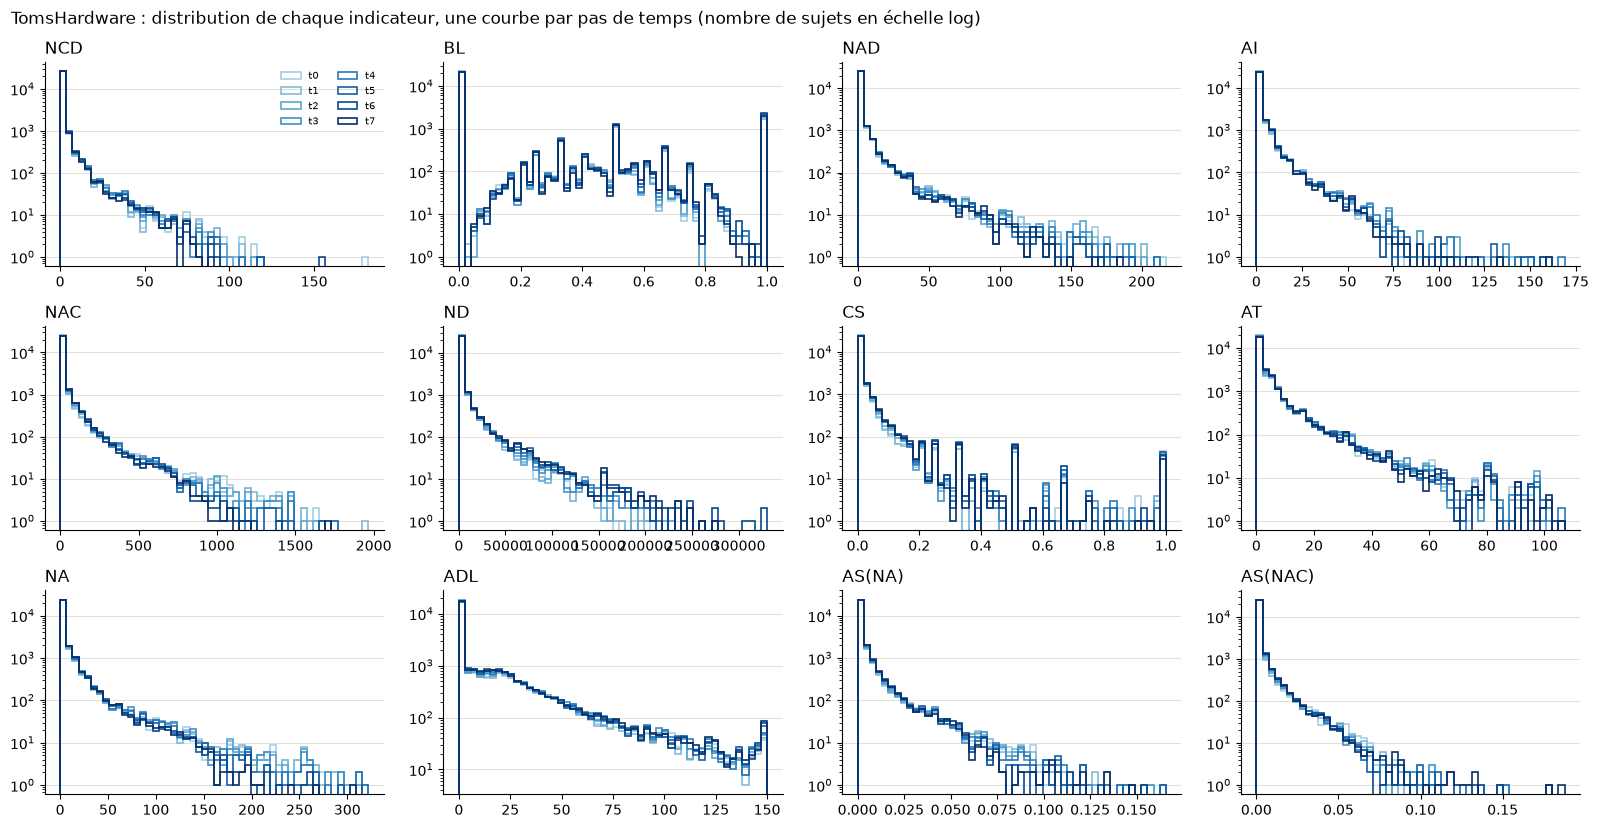

In [7]:
def histogrammes_attributs(nom, df, ncols=4):
    spec = DATASETS[nom]
    inds, n_steps = spec["indicateurs"], spec["n_steps"]
    nrows = -(-len(inds) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.8 * nrows))
    couleurs = plt.cm.Blues(np.linspace(0.35, 1, n_steps))  # clair = t0, foncé = dernier pas
    for ax, ind in zip(axes.flat, inds):
        cols = [f"{ind}_{t}" for t in range(n_steps)]
        bins = np.histogram_bin_edges(df[cols].to_numpy().ravel(), bins=50)
        for t, col in enumerate(cols):
            ax.hist(df[col], bins=bins, histtype="step", color=couleurs[t], linewidth=1.2, label=f"t{t}")
        ax.set_yscale("log")
        ax.set_title(ind)
    for ax in axes.flat[len(inds):]:
        ax.axis("off")
    axes.flat[0].legend(fontsize=7, ncol=2, frameon=False)
    fig.suptitle(f"{nom} : distribution de chaque indicateur, une courbe par pas de temps (nombre de sujets en échelle log)",
                 x=0.01, ha="left")
    fig.tight_layout()
    plt.show()


for nom, df in data.items():
    histogrammes_attributs(nom, df)

Deux constats.

**Les pas de temps d'un même indicateur ont la même distribution.** Sur chaque panneau, les 7 ou 8 courbes se superposent, à un léger décalage près sur Twitter où les derniers pas ont une queue un peu plus lourde, l'activité augmentant au fil de la fenêtre. Un indicateur se comporte donc de la même façon quel que soit le pas, et toute transformation qu'on lui appliquera devra être la même sur toutes ses colonnes.

**Les attributs sont aussi déséquilibrés que la cible.** Les indicateurs de comptage (NCD, AI, NAC, NA, NAD, ND) ont la même forme que la cible : presque tous les sujets dans la première barre, puis une queue qui s'étire jusqu'à 79 000 sur Twitter et 330 000 affichages sur Tom's Hardware. Sur Tom's Hardware, plus de 60 % des valeurs sont à 0 pour tout sauf ND. Les ratios sont bornés et se comportent autrement : BL et CS valent presque toujours 1 sur Twitter, où une discussion est le plus souvent un tweet unique, alors que BL s'étale sur [0, 1] sur le forum. AT et ADL sont concentrés sur de petites valeurs avec une queue modérée.

Faut-il changer l'échelle des attributs comme on l'a fait pour la cible ? Cela dépend du modèle. Les méthodes à base d'arbres, qu'on utilisera pour exploiter tous les attributs, n'y sont pas sensibles : un arbre coupe un attribut à un seuil et ne considère que l'ordre des valeurs, qu'une transformation croissante comme le log conserve. Les coupures, donc les prédictions, sont identiques. La question se posera pour la régression linéaire, utilisée plus loin en comparaison, où la valeur elle-même compte ; on y passera les comptages en log.

### 4.3 Une seule série : trois modèles naïfs

La cible est la moyenne, sur la période qui suit la fenêtre, d'un indicateur présent dans les attributs : NAD sur Twitter, ND sur Tom's Hardware. Les trois modèles de cette section n'utilisent que cette série, c'est-à-dire une seule colonne par pas de temps, et aucune information provenant des autres sujets : chaque sujet est prédit à partir de ses seules 7 ou 8 valeurs. On note $v_0, \dots, v_{n-1}$ ces valeurs, avec $n = 7$ sur Twitter et $n = 8$ sur Tom's Hardware.

1. **Dernière valeur** : $\hat{y} = v_{n-1}$.
2. **Tendance linéaire** : on ajuste $v_t \approx a + b\,t$ par moindres carrés sur les $n$ pas, puis on évalue la droite aux pas à prédire.
3. **Tendance exponentielle** : on ajuste $\log(1 + v_t) \approx a + b\,t$, soit $1 + v_t \approx e^{a} e^{b t}$. Le taux $b$ est estimé pour chaque sujet ; c'est lui qui distingue une croissance rapide d'une croissance lente.

Les modèles 2 et 3 demandent de fixer les pas à prédire. La documentation indique que la cible est calculée sur « les deux semaines suivantes » sans préciser la durée d'un pas ; on retient la moyenne de la droite aux pas $n$ et $n + 1$. La durée réelle d'un pas est sans effet, les calculs étant faits en unités de pas ; seul compte le nombre de pas entre la fin de la fenêtre et la cible, et la sensibilité à ce choix est examinée ci-dessous.

Les mesures sont calculées sur les 20 % de sujets réservés au test, les mêmes pour tous les modèles du notebook : R², RMSE sur le log, erreur multiplicative médiane, c'est-à-dire l'exponentielle de la médiane de l'erreur absolue sur le log, lue comme un facteur, et corrélation entre prédiction et réalité sur le log.

In [8]:
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

INDICATEUR_CIBLE = {"Twitter": "NAD", "TomsHardware": "ND"}


def decouper(df, test_size=0.2, seed=0):
    X = df.drop(columns="cible")
    y = np.log1p(df["cible"])
    return train_test_split(X, y, test_size=test_size, random_state=seed)


def scores(y_vrai, y_pred):
    err = y_pred - y_vrai
    return {
        "R²": r2_score(y_vrai, y_pred),
        "RMSE (log)": np.sqrt(np.mean(err**2)),
        "erreur multiplicative médiane": np.exp(np.median(np.abs(err))),
        "corrélation (log)": np.corrcoef(y_vrai, y_pred)[0, 1],
    }


def tendance(V, t, horizon):
    """Droite a + b·t ajustée par moindres carrés sur chaque ligne de V, moyennée sur les pas de `horizon`."""
    tc = t - t.mean()
    b = V @ tc / (tc @ tc)
    a = V.mean(axis=1) - b * t.mean()
    return np.mean([a + b * h for h in horizon], axis=0)


def serie_cible(nom, X):
    return X[[f"{INDICATEUR_CIBLE[nom]}_{t}" for t in range(DATASETS[nom]["n_steps"])]].to_numpy(dtype=float)


def modeles_naifs(nom, X):
    """Prédictions de log(1 + cible) à partir de la seule série de l'indicateur cible."""
    V = serie_cible(nom, X)
    n = V.shape[1]
    t, horizon = np.arange(n), [n, n + 1]  # hypothèse : la cible est la moyenne des deux pas suivants
    return {
        "dernière valeur": np.log1p(V[:, -1]),
        "tendance linéaire": np.log1p(np.clip(tendance(V, t, horizon), 0, None)),
        "tendance exponentielle": np.clip(tendance(np.log1p(V), t, horizon), 0, None),
    }


jeux, predictions, resultats = {}, {}, {}
for nom, df in data.items():
    X_app, X_test, y_app, y_test = jeux[nom] = decouper(df)
    for modele, y_pred in modeles_naifs(nom, X_test).items():
        predictions[(nom, modele)] = (y_test.to_numpy(), y_pred)
        resultats[(nom, modele, "test")] = scores(y_test, y_pred)

pd.DataFrame(resultats).T.round(3)

R²  RMSE (log)  \
Twitter      dernière valeur        test  0.892       0.660   
             tendance linéaire      test  0.886       0.680   
             tendance exponentielle test  0.876       0.708   
TomsHardware dernière valeur        test  0.976       0.368   
             tendance linéaire      test  0.968       0.424   
             tendance exponentielle test  0.965       0.439   

                                          erreur multiplicative médiane  \
Twitter      dernière valeur        test                          1.417   
             tendance linéaire      test                          1.495   
             tendance exponentielle test                          1.518   
TomsHardware dernière valeur        test                          1.177   
             tendance linéaire      test                          1.261   
             tendance exponentielle test                          1.285   

                                          corrélation (log)  
Twitter      dernière valeur        test              0.950  
             tendance linéaire      test              0.960  
             tendance exponentielle test              0.953  
TomsHardware dernière valeur        test              0.989  
             tendance linéaire      test              0.989  
             tendance exponentielle test              0.988

In [9]:
# Sensibilité au pas d'évaluation : RMSE (log) des deux tendances selon l'écart entre le pas où l'on
# évalue la droite et le dernier pas observé (+1,5 correspond à l'hypothèse retenue ci-dessus).
def rmse(y, y_pred):
    return np.sqrt(np.mean((y_pred - y) ** 2))


sensibilite = {}
for nom in data:
    _, X_test, _, y_test = jeux[nom]
    V = serie_cible(nom, X_test)
    n = V.shape[1]
    t = np.arange(n)
    for ecart in [-1, 0, 1, 1.5, 2, 3]:
        h = n - 1 + ecart
        sensibilite[(nom, f"{ecart:+g} pas")] = {
            "tendance linéaire": rmse(y_test, np.log1p(np.clip(tendance(V, t, [h]), 0, None))),
            "tendance exponentielle": rmse(y_test, np.clip(tendance(np.log1p(V), t, [h]), 0, None)),
        }
    sensibilite[(nom, "dernière valeur")] = {"tendance linéaire": rmse(y_test, np.log1p(V[:, -1])),
                                             "tendance exponentielle": rmse(y_test, np.log1p(V[:, -1]))}
pd.DataFrame(sensibilite).T.round(3)

tendance linéaire  tendance exponentielle
Twitter      -1 pas                       0.570                   0.528
             +0 pas                       0.613                   0.583
             +1 pas                       0.657                   0.662
             +1.5 pas                     0.680                   0.708
             +2 pas                       0.703                   0.757
             +3 pas                       0.749                   0.863
             dernière valeur              0.660                   0.660
TomsHardware -1 pas                       0.359                   0.341
             +0 pas                       0.382                   0.368
             +1 pas                       0.409                   0.412
             +1.5 pas                     0.424                   0.439
             +2 pas                       0.439                   0.469
             +3 pas                       0.472                   0.533
             dernière valeur              0.368                   0.368

La dernière valeur est le meilleur des trois modèles, sur les deux jeux de données et pour les trois mesures d'erreur : R² de 0,892 sur Twitter et 0,976 sur Tom's Hardware, erreur typique d'un facteur 1,42 et 1,18. Les deux tendances font moins bien, l'exponentielle étant la moins bonne, avec un R² de 0,876 et 0,965. Une droite ajustée sur 7 ou 8 valeurs bruitées puis prolongée au-delà de la fenêtre amplifie ce qui se passait en fin de fenêtre ; sur l'échelle log, cet excès devient multiplicatif. La tendance linéaire obtient pourtant la meilleure corrélation sur Twitter, 0,960 contre 0,950 : elle ordonne légèrement mieux les sujets parce qu'elle lisse les valeurs entières de la dernière observation, mais ses débordements lui coûtent davantage en erreur que ce lissage ne lui rapporte.

Le tableau de sensibilité précise ce résultat. L'erreur des deux tendances diminue de façon monotone quand on recule le pas d'évaluation, y compris à l'intérieur de la fenêtre : la droite évaluée un pas avant la dernière observation fait mieux que la dernière valeur elle-même, 0,53 contre 0,66 sur Twitter, 0,34 contre 0,37 sur Tom's Hardware. Les données ne permettent donc pas d'identifier l'horizon de la cible ; le pas d'évaluation agit comme un paramètre de lissage et non comme un temps. L'extrapolation nuit, le lissage aide, et l'hypothèse d'horizon retenue ne favorise pas les tendances. L'idée d'une dynamique exponentielle du buzz, plausible a priori, ne se traduit pas en meilleure prédiction à cet horizon : les séries sont courtes et bruitées, et la persistance domine. Avec une seule série, le modèle le plus simple est le plus difficile à battre.

### 4.4 Plusieurs séries : corrélations entre indicateurs

Avant d'utiliser toutes les séries dans un modèle, on examine ce qu'elles disent les unes des autres. Deux redondances sont possibles : entre indicateurs, et pour un même indicateur d'un pas de temps au suivant. On mesure les deux par la corrélation de Spearman, qui ne dépend que des rangs, donc ni des échelles ni des queues de distribution. Ces redondances ne gênent pas un modèle à base d'arbres, mais elles conditionnent l'interprétation : ce qu'un modèle tire d'un indicateur, il aurait pu le tirer d'un indicateur redondant.

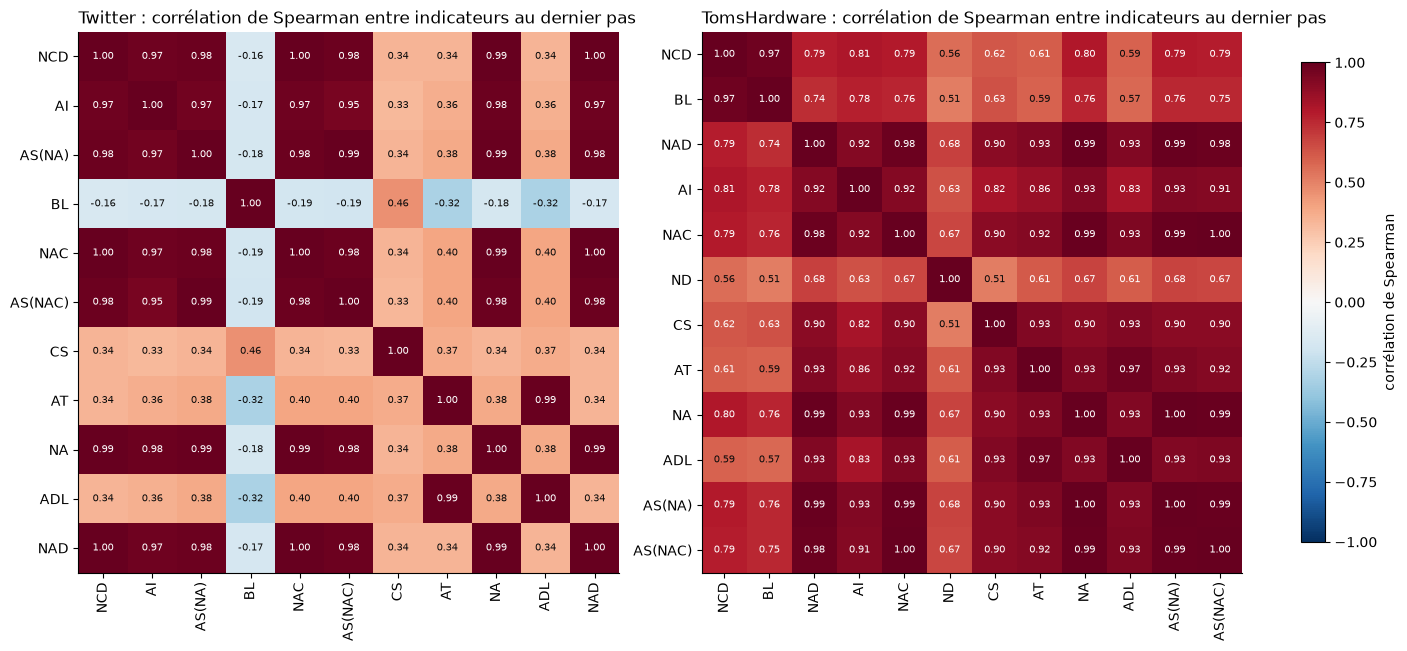

In [10]:
def correlations_dernier_pas(nom, df):
    spec = DATASETS[nom]
    cols = [f"{ind}_{spec['n_steps'] - 1}" for ind in spec["indicateurs"]]
    return df[cols].corr(method="spearman").set_axis(spec["indicateurs"], axis=0).set_axis(spec["indicateurs"], axis=1)


fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), constrained_layout=True)
for ax, (nom, df) in zip(axes, data.items()):
    corr = correlations_dernier_pas(nom, df)
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
    ax.set_yticks(range(len(corr)), corr.index)
    ax.grid(False)
    for i in range(len(corr)):
        for j in range(len(corr)):
            v = corr.iat[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 else "#0b0b0b")
    ax.set_title(f"{nom} : corrélation de Spearman entre indicateurs au dernier pas")
fig.colorbar(im, ax=axes, shrink=0.8, label="corrélation de Spearman")
plt.show()

In [11]:
def correlation_pas_consecutifs(nom, df):
    """Corrélation de Spearman d'un indicateur avec lui-même d'un pas au suivant, moyennée sur les pas."""
    spec = DATASETS[nom]
    return pd.Series({
        ind: np.mean([df[f"{ind}_{t}"].corr(df[f"{ind}_{t + 1}"], method="spearman") for t in range(spec["n_steps"] - 1)])
        for ind in spec["indicateurs"]
    }, name=nom)


pd.concat([correlation_pas_consecutifs(nom, df) for nom, df in data.items()], axis=1).round(2).astype(object).fillna("–")

,Twitter,TomsHardware
NCD,0.92,0.59
AI,0.91,0.62
AS(NA),0.92,0.72
BL,0.35,0.44
NAC,0.92,0.71
AS(NAC),0.92,0.71
CS,0.19,0.54
AT,0.63,0.61
NA,0.92,0.72
ADL,0.64,0.63


Sur Twitter, sept indicateurs sur onze disent la même chose : NCD, AI, AS(NA), NAC, AS(NAC), NA et NAD sont corrélés entre 0,95 et 1,00. C'est la conséquence de ce qu'on a vu plus haut : une discussion y est le plus souvent un tweet unique, donc discussions, contributions, auteurs et parts d'attention se confondent. AT et ADL forment un deuxième groupe, corrélés à 0,99 entre eux et à 0,35 seulement avec le premier. BL et CS, faiblement liés à tout le reste, un troisième. Les 77 colonnes de Twitter décrivent en réalité trois choses : un volume, une forme de discussion, une irrégularité.

Sur Tom's Hardware, le bloc est encore plus large, huit indicateurs corrélés au-delà de 0,90, parce que 60 % des valeurs sont nulles : le rang y est surtout une question de sujet actif ou inactif, et tous les indicateurs d'écriture s'annulent ensemble. Deux exceptions. NCD et BL, le flux de nouveaux fils, se détachent un peu. Et surtout ND, le nombre d'affichages, qui est l'indicateur cible, n'est corrélé qu'entre 0,51 et 0,68 au reste : lecture et écriture sont deux dynamiques différentes sur le forum. On s'attend donc à ce que les attributs d'écriture aident peu à prédire ND.

D'un pas de temps au suivant, les indicateurs de volume se ressemblent beaucoup sur Twitter, 0,91 à 0,92, et ND est presque constant sur le forum, 0,99, ce qui laisse présager qu'un modèle qui reporte simplement la dernière valeur sera difficile à battre sur Tom's Hardware. Les ratios BL et CS sont les plus instables, 0,19 à 0,54. Conséquence pour la suite : les colonnes d'un même indicateur sont redondantes entre elles, et les indicateurs d'un même bloc le sont entre eux. L'importance des variables devra se lire par bloc, pas colonne par colonne.

En résumé, sur Twitter l'activité autour d'un sujet se réduit à son volume de tweets, auquel auteurs, contributions et attention sont proportionnels ; la forme des discussions en est indépendante. Sur Tom's Hardware, l'écriture, fils, messages et auteurs, forme un bloc, et la lecture, les affichages, en est largement découplée : un fil peut être lu longtemps après avoir cessé d'être alimenté. La cible du forum étant la lecture, les attributs d'écriture ne devraient apporter qu'une information limitée, alors que sur Twitter la cible appartient au bloc dominant.

### 4.5 Toutes les séries : une méthode à base d'arbres

On utilise maintenant toutes les colonnes. Le modèle est un gradient boosting d'arbres, `HistGradientBoostingRegressor` de scikit-learn, avec ses paramètres par défaut, entraîné sur les 80 % de sujets d'apprentissage pour prédire log(1 + cible), et évalué sur le même jeu de test que les modèles naïfs, avec les mêmes mesures. Le score d'apprentissage est donné pour contrôler le surapprentissage. Les doublons exacts peuvent se trouver des deux côtés du découpage et favoriser légèrement le score de test ; ils représentent 1 % des lignes.

In [12]:
from sklearn.ensemble import HistGradientBoostingRegressor

modeles = {}
for nom, df in data.items():
    X_app, X_test, y_app, y_test = jeux[nom]
    modeles[nom] = HistGradientBoostingRegressor(random_state=0).fit(X_app, y_app)
    predictions[(nom, "gradient boosting")] = (y_test.to_numpy(), modeles[nom].predict(X_test))
    resultats[(nom, "gradient boosting", "apprentissage")] = scores(y_app, modeles[nom].predict(X_app))
    resultats[(nom, "gradient boosting", "test")] = scores(*predictions[(nom, "gradient boosting")])


def tableau_scores(resultats):
    t = pd.DataFrame(resultats).T
    return t.loc[[cle for nom in data for cle in t.index if cle[0] == nom]].round(3)


tableau_scores(resultats)

R²  RMSE (log)  \
Twitter      dernière valeur        test           0.892       0.660   
             tendance linéaire      test           0.886       0.680   
             tendance exponentielle test           0.876       0.708   
             gradient boosting      apprentissage  0.946       0.468   
                                    test           0.945       0.471   
TomsHardware dernière valeur        test           0.976       0.368   
             tendance linéaire      test           0.968       0.424   
             tendance exponentielle test           0.965       0.439   
             gradient boosting      apprentissage  0.987       0.272   
                                    test           0.984       0.299   

                                                   erreur multiplicative médiane  \
Twitter      dernière valeur        test                                   1.417   
             tendance linéaire      test                                   1.495   
             tendance exponentielle test                                   1.518   
             gradient boosting      apprentissage                          1.278   
                                    test                                   1.279   
TomsHardware dernière valeur        test                                   1.177   
             tendance linéaire      test                                   1.261   
             tendance exponentielle test                                   1.285   
             gradient boosting      apprentissage                          1.136   
                                    test                                   1.146   

                                                   corrélation (log)  
Twitter      dernière valeur        test                       0.950  
             tendance linéaire      test                       0.960  
             tendance exponentielle test                       0.953  
             gradient boosting      apprentissage              0.972  
                                    test                       0.972  
TomsHardware dernière valeur        test                       0.989  
             tendance linéaire      test                       0.989  
             tendance exponentielle test                       0.988  
             gradient boosting      apprentissage              0.993  
                                    test                       0.992

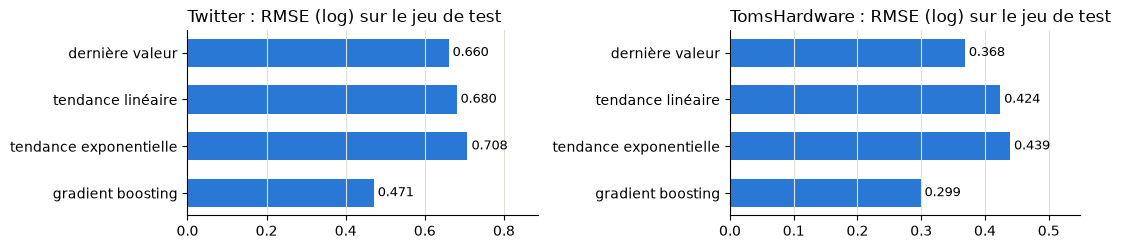

In [13]:
def figure_scores(resultats, mesure="RMSE (log)"):
    """Un panneau par dataset, une barre par modèle : la mesure sur le jeu de test."""
    t = pd.DataFrame(resultats).T
    fig, axes = plt.subplots(1, 2, figsize=(11, 0.6 + 0.5 * t.index.get_level_values(1).nunique()))
    for ax, nom in zip(axes, data):
        s = t.loc[nom].xs("test", level=1)[mesure][::-1]
        ax.barh(s.index, s.values, color=BLEU, height=0.6)
        for i, v in enumerate(s.values):
            ax.text(v, i, f" {v:.3f}", va="center", fontsize=9)
        ax.set_xlim(0, s.max() * 1.25)
        ax.set_title(f"{nom} : {mesure} sur le jeu de test")
        ax.grid(False)
        ax.grid(True, axis="x")
    fig.tight_layout()
    plt.show()


figure_scores(resultats)

Le gradient boosting fait mieux que la dernière valeur sur les deux jeux de données. Sur Twitter, le R² passe de 0,892 à 0,945 et la RMSE sur le log de 0,66 à 0,47, soit une baisse de 29 % ; l'erreur typique passe d'un facteur 1,42 à 1,28. Sur Tom's Hardware, le R² passe de 0,976 à 0,984 et la RMSE de 0,37 à 0,30, soit 19 % de moins. Les scores d'apprentissage et de test sont voisins : pas de surapprentissage.

L'essentiel du score reste dû à la persistance, que la dernière valeur capte déjà. Les autres attributs apportent un complément net sur Twitter et plus faible sur Tom's Hardware, conformément à ce que la structure de corrélation laissait attendre. Une partie de l'erreur résiduelle sur Twitter est irréductible : plus de 13 000 lignes y ont des attributs identiques à ceux d'une autre ligne pour une cible différente, et aucun modèle ne peut les distinguer.

### 4.6 D'autres méthodes de régression

Pour situer le gradient boosting, on compare deux autres modèles sur les mêmes jeux d'apprentissage et de test : une régression linéaire et une forêt aléatoire.

Pour la régression linéaire, les attributs sont mis à l'échelle comme annoncé dans la section sur les attributs : comptages et moyennes par discussion en log(1 + x), ratios inchangés, puis centrage et réduction de toutes les colonnes. On utilise la variante ridge, qui ajoute aux moindres carrés une pénalité sur la taille des coefficients. Elle stabilise l'ajustement quand les attributs sont fortement corrélés, ce qui est le cas ici, et avec une pénalité faible sur plusieurs centaines de milliers de lignes elle se confond pratiquement avec les moindres carrés ordinaires. La forêt aléatoire est limitée à 50 arbres, chacun construit sur la moitié des sujets d'apprentissage, afin de tenir en temps raisonnable sur Twitter.

In [14]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

EN_LOG = {"NCD", "AI", "NAC", "NA", "NAD", "ND", "AT", "ADL"}  # comptages et moyennes par discussion


def passer_en_log(X):
    X = X.copy()
    cols = [c for c in X.columns if c.split("_")[0] in EN_LOG]
    X[cols] = np.log1p(X[cols])
    return X


for nom in data:
    X_app, X_test, y_app, y_test = jeux[nom]
    essais = {
        "régression linéaire": (make_pipeline(StandardScaler(), Ridge(alpha=1.0)), passer_en_log(X_app), passer_en_log(X_test)),
        "forêt aléatoire": (RandomForestRegressor(n_estimators=50, min_samples_leaf=10, max_features=0.33,
                                                  max_samples=0.5, n_jobs=-1, random_state=0), X_app, X_test),
    }
    for modele, (m, Xa, Xt) in essais.items():
        m.fit(Xa, y_app)
        predictions[(nom, modele)] = (y_test.to_numpy(), m.predict(Xt))
        resultats[(nom, modele, "test")] = scores(*predictions[(nom, modele)])

tableau_scores(resultats)

R²  RMSE (log)  \
Twitter      dernière valeur        test           0.892       0.660   
             tendance linéaire      test           0.886       0.680   
             tendance exponentielle test           0.876       0.708   
             gradient boosting      apprentissage  0.946       0.468   
                                    test           0.945       0.471   
             régression linéaire    test           0.941       0.487   
             forêt aléatoire        test           0.946       0.469   
TomsHardware dernière valeur        test           0.976       0.368   
             tendance linéaire      test           0.968       0.424   
             tendance exponentielle test           0.965       0.439   
             gradient boosting      apprentissage  0.987       0.272   
                                    test           0.984       0.299   
             régression linéaire    test           0.983       0.305   
             forêt aléatoire        test           0.983       0.304   

                                                   erreur multiplicative médiane  \
Twitter      dernière valeur        test                                   1.417   
             tendance linéaire      test                                   1.495   
             tendance exponentielle test                                   1.518   
             gradient boosting      apprentissage                          1.278   
                                    test                                   1.279   
             régression linéaire    test                                   1.304   
             forêt aléatoire        test                                   1.274   
TomsHardware dernière valeur        test                                   1.177   
             tendance linéaire      test                                   1.261   
             tendance exponentielle test                                   1.285   
             gradient boosting      apprentissage                          1.136   
                                    test                                   1.146   
             régression linéaire    test                                   1.144   
             forêt aléatoire        test                                   1.143   

                                                   corrélation (log)  
Twitter      dernière valeur        test                       0.950  
             tendance linéaire      test                       0.960  
             tendance exponentielle test                       0.953  
             gradient boosting      apprentissage              0.972  
                                    test                       0.972  
             régression linéaire    test                       0.970  
             forêt aléatoire        test                       0.972  
TomsHardware dernière valeur        test                       0.989  
             tendance linéaire      test                       0.989  
             tendance exponentielle test                       0.988  
             gradient boosting      apprentissage              0.993  
                                    test                       0.992  
             régression linéaire    test                       0.992  
             forêt aléatoire        test                       0.992

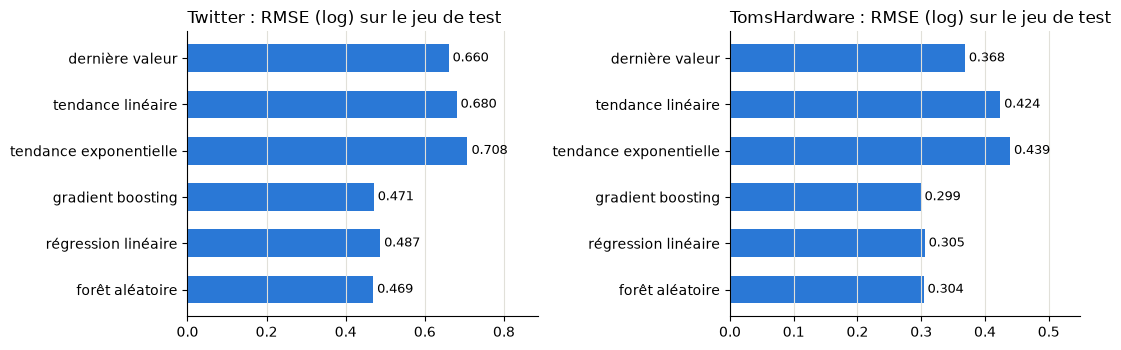

In [15]:
figure_scores(resultats)

Deux enseignements. D'abord, trois modèles de familles différentes, régression linéaire sur attributs en log, gradient boosting et forêt aléatoire, convergent vers la même erreur : R² de 0,941 à 0,946 sur Twitter, 0,983 à 0,984 sur Tom's Hardware, RMSE de 0,47 à 0,49 et de 0,30 à 0,31. Cette convergence indique que l'erreur résiduelle tient aux données, bruit ou information absente, et non au choix du modèle.

Ensuite, qu'un modèle linéaire sur les logarithmes fasse presque aussi bien que les arbres signifie que la relation entre attributs et cible est, en échelle log, à peu près additive : les modèles d'arbres n'exploitent que peu d'interactions entre attributs. Le changement d'échelle, sans effet sur les arbres, est en revanche ce qui rend le modèle linéaire compétitif : sans lui, quelques sujets énormes domineraient l'ajustement.

## 5. Comparatif des modèles de prédiction entre Twitter et Tom's Hardware

Le tableau rassemble, pour chaque réseau, les résultats établis dans les sections précédentes.

| | Twitter | Tom's Hardware |
|---|---|---|
| Sujets | 583 250 | 28 179 |
| Indicateurs × pas de temps | 11 × 7 | 12 × 8 |
| Cible | discussions actives (NAD) | affichages (ND) |
| Médiane et maximum de la cible | 26 et 75 724 | 359 et 265 916 |
| Structure des indicateurs | trois blocs : volume, forme des discussions, irrégularité | écriture et lecture découplées ; la cible est la lecture |
| Persistance de l'indicateur cible d'un pas au suivant (Spearman) | 0,92 | 0,99 |
| Dernière valeur : R² | 0,892 | 0,976 |
| Meilleur modèle sur tous les attributs : R² | 0,946 | 0,984 |
| Baisse de RMSE apportée par les attributs | 29 % | 19 % |
| Erreur typique du meilleur modèle | facteur 1,27 | facteur 1,14 |
| Lignes aux attributs identiques et cibles différentes | 13 493 | 72 |

Tom's Hardware est le réseau le plus prévisible : la persistance y est presque totale, 0,99 d'un pas au suivant, et la seule dernière valeur explique 97,6 % de la variance du log. C'est aussi celui où les attributs apportent le moins. La lecture d'un forum obéit à sa propre dynamique, découplée de l'écriture : les fils continuent d'être consultés qu'ils soient ou non alimentés, et les indicateurs d'écriture n'en disent pas grand-chose. L'hypothèse formulée dans l'objectif, des dynamiques plus conservatrices, se vérifie : l'activité y varie peu d'une période à l'autre, et prédire le buzz y revient surtout à reporter l'activité présente.

Twitter est moins prévisible, persistance de 0,92 et R² de 0,89 pour la dernière valeur, mais c'est le réseau où l'information au-delà de la persistance compte le plus : les attributs y réduisent l'erreur de 29 %. La contrepartie est un plancher de bruit élevé : plus de 13 000 lignes, des sujets à très faible activité, ont des attributs identiques pour des cibles différentes, et le modèle plafonne sur les sujets les plus gros, trop rares pour être appris.

Sur les deux réseaux, les conclusions de méthode sont les mêmes. Le logarithme est la bonne échelle pour la cible, et pour les attributs des modèles linéaires. Extrapoler une tendance ajustée sur la fenêtre nuit, lisser aide. Régression linéaire sur log, gradient boosting et forêt aléatoire convergent vers la même erreur, ce qui situe la limite dans les données et non dans le modèle.

## 6. Reconnaître le réseau à la dynamique d'un sujet : classification

Les sections précédentes ont décrit chaque réseau séparément. Pour mesurer à quel point leurs dynamiques diffèrent, on retourne le problème : peut-on reconnaître le réseau d'un sujet à partir de ses seuls attributs ? Si un classifieur y parvient, les deux réseaux diffèrent structurellement, et ce qu'il utilise dit en quoi. C'est une question de classification au sens propre : la classe n'est pas une fonction de la cible, et aucune régression ne la fournit.

La réponse brute est sans intérêt : les échelles, la densité d'activité et la structure des discussions séparent les deux réseaux à vue. On procède donc par paliers, en retirant à chaque fois ce qui les distingue de façon évidente, pour voir ce qui reste.

1. Tous les attributs communs, c'est-à-dire les neuf indicateurs présents sur les deux réseaux, NCD, AI, NAC, NA, NAD, BL, CS, AT, ADL, sur les sept derniers pas de temps, tous sujets confondus. ND n'existe que sur le forum ; AS(NA) et AS(NAC) sont des parts de l'activité totale de chaque plateforme, donc incomparables d'un réseau à l'autre.
2. Les mêmes, mais seulement pour les sujets dont NAD est non nul à chaque pas, ce qui retire la différence de densité d'activité.
3. La forme des cinq indicateurs de volume, chaque série divisée par son maximum, ce qui retire les échelles.
4. La forme de l'indicateur cible de chaque réseau, NAD sur Twitter et ND sur le forum, pour les sujets où il est non nul à chaque pas. C'est la comparaison des signaux de popularité eux-mêmes, ceux sur lesquels les cibles sont définies ; elle retire aussi la structure des discussions, puisque NCD, NAC et NAD se confondent sur Twitter et pas sur le forum.
5. Quatre descripteurs de la dynamique de cet indicateur, calculés sur le logarithme de la série : pente sur la fenêtre, amplitude, variation d'un pas au suivant en médiane et en maximum. S'ils suffisent, la différence restante est entièrement décrite.

Le classifieur est un gradient boosting avec pondération équilibrée des classes. Twitter est sous-échantillonné à 40 000 sujets, ce qui ne change pas l'AUC et garde le calcul court. On rapporte l'AUC et l'exactitude équilibrée, moyenne des taux de bonne classification des deux réseaux.

In [16]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import balanced_accuracy_score, roc_auc_score

COMMUNS_VOLUME = ["NCD", "AI", "NAC", "NA", "NAD"]
COMMUNS_FORME = ["BL", "CS", "AT", "ADL"]
K = 7  # pas de temps communs : les 7 derniers de chaque fenêtre


def forme_serie(S):
    """Chaque ligne divisée par son maximum : la forme de la série, sans son échelle."""
    V = S.to_numpy(dtype=float)
    m = V.max(axis=1, keepdims=True)
    return pd.DataFrame(np.divide(V, m, out=np.zeros_like(V), where=m > 0), columns=S.columns, index=S.index)


def attributs_communs(nom, df):
    """Les neuf indicateurs communs sur les 7 derniers pas : valeurs brutes, formes des volumes, sujets actifs à chaque pas."""
    n = DATASETS[nom]["n_steps"]
    pas = range(n - K, n)
    brut = pd.DataFrame({f"{ind}_{k}": df[f"{ind}_{t}"].to_numpy()
                         for ind in COMMUNS_VOLUME + COMMUNS_FORME for k, t in enumerate(pas)})
    forme = pd.concat([forme_serie(brut[[f"{ind}_{k}" for k in range(K)]]) for ind in COMMUNS_VOLUME], axis=1)
    actif = (brut[[f"NAD_{k}" for k in range(K)]] > 0).all(axis=1)
    return brut, forme, actif


def serie_cible_commune(nom, df):
    """L'indicateur cible du réseau, NAD ou ND, sur les 7 derniers pas."""
    n = DATASETS[nom]["n_steps"]
    return pd.DataFrame({f"cible_{k}": df[f"{INDICATEUR_CIBLE[nom]}_{t}"].to_numpy() for k, t in enumerate(range(n - K, n))})


def descripteurs(S):
    """Quatre descripteurs de la dynamique d'une série strictement positive, sur son logarithme."""
    L = np.log(S.to_numpy(dtype=float))
    dL = np.abs(np.diff(L, axis=1))
    return pd.DataFrame({
        "pente (log par pas)": np.polyfit(np.arange(K), L.T, 1)[0],
        "amplitude log(max / min)": L.max(axis=1) - L.min(axis=1),
        "variation médiane d'un pas au suivant": np.median(dL, axis=1),
        "variation maximale d'un pas au suivant": dL.max(axis=1),
    }, index=S.index)


def reconnaitre(X, y):
    X_app, X_test, y_app, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
    proba = HistGradientBoostingClassifier(random_state=0, class_weight="balanced").fit(X_app, y_app).predict_proba(X_test)[:, 1]
    return {"sujets du forum": int((y == 0).sum()), "sujets Twitter": int((y == 1).sum()),
            "AUC": roc_auc_score(y_test, proba), "exactitude équilibrée": balanced_accuracy_score(y_test, proba > 0.5)}


rng = np.random.RandomState(0)
choix = {"Twitter": rng.choice(len(data["Twitter"]), 40000, replace=False),
         "TomsHardware": np.arange(len(data["TomsHardware"]))}
parts = {nom: attributs_communs(nom, df) for nom, df in data.items()}
brut = pd.concat([parts[nom][0].iloc[choix[nom]] for nom in data], ignore_index=True)
forme = pd.concat([parts[nom][1].iloc[choix[nom]] for nom in data], ignore_index=True)
actif = pd.concat([parts[nom][2].iloc[choix[nom]] for nom in data], ignore_index=True).to_numpy()
cible_s = pd.concat([serie_cible_commune(nom, df).iloc[choix[nom]] for nom, df in data.items()], ignore_index=True)
actif_cible = (cible_s > 0).all(axis=1).to_numpy()
reseau = pd.Series(np.concatenate([np.full(len(choix[nom]), int(nom == "Twitter")) for nom in data]))  # 1 = Twitter, 0 = forum

paliers = {
    "1. attributs communs, tous les sujets": (brut, reseau),
    "2. attributs communs, sujets dont NAD est non nul à chaque pas": (brut[actif], reseau[actif]),
    "3. forme des cinq volumes, mêmes sujets": (forme[actif], reseau[actif]),
    "4. forme de l'indicateur cible, sujets où il est non nul à chaque pas": (forme_serie(cible_s[actif_cible]), reseau[actif_cible]),
    "5. quatre descripteurs de l'indicateur cible, mêmes sujets": (descripteurs(cible_s[actif_cible]), reseau[actif_cible]),
}
tableau_paliers = pd.DataFrame({p: reconnaitre(X, y) for p, (X, y) in paliers.items()}).T
tableau_paliers.round(3)

,sujets du forum,sujets Twitter,AUC,exactitude équilibrée
"1. attributs communs, tous les sujets",28179.0,40000.0,1.000,1.000
"2. attributs communs, sujets dont NAD est non nul à chaque pas",4967.0,31343.0,1.000,1.000
"3. forme des cinq volumes, mêmes sujets",4967.0,31343.0,0.999,0.990
"4. forme de l'indicateur cible, sujets où il est non nul à chaque pas",27183.0,31343.0,0.815,0.740
"5. quatre descripteurs de l'indicateur cible, mêmes sujets",27183.0,31343.0,0.797,0.727


,TomsHardware,Twitter
médiane par réseau,,
pente (log par pas),0.061,0.080
amplitude log(max / min),0.647,1.191
variation médiane d'un pas au suivant,0.162,0.347
variation maximale d'un pas au suivant,0.447,0.916


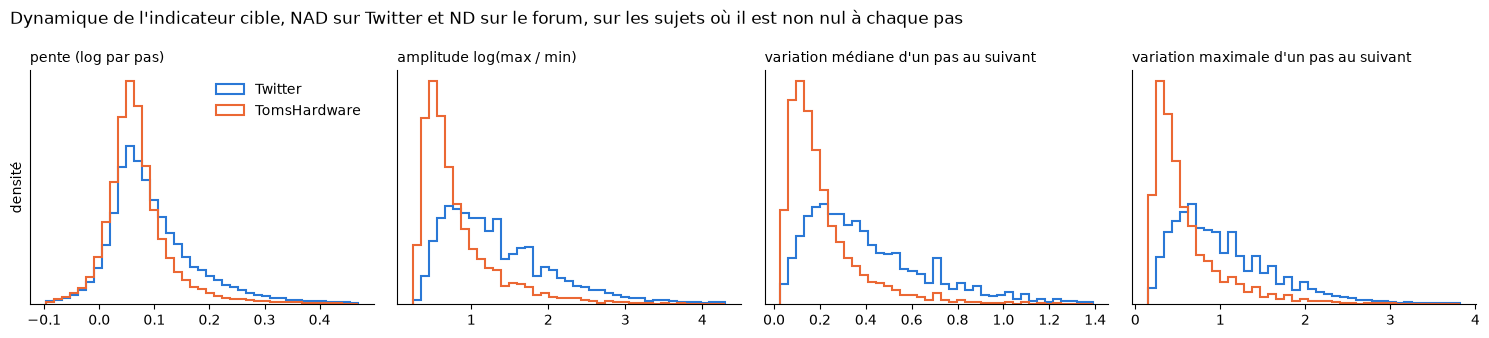

In [17]:
D = descripteurs(cible_s[actif_cible])
etiquette = np.where(reseau[actif_cible].to_numpy() == 1, "Twitter", "TomsHardware")
display(D.groupby(etiquette).median().T.round(3).rename_axis("médiane par réseau"))

ORANGE = "#eb6834"
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, col in zip(axes, D.columns):
    lo, hi = D[col].quantile([0.005, 0.995])
    bins = np.linspace(lo, hi, 40)
    for nom, couleur in [("Twitter", BLEU), ("TomsHardware", ORANGE)]:
        ax.hist(D.loc[etiquette == nom, col], bins=bins, density=True, histtype="step", linewidth=1.5, color=couleur, label=nom)
    ax.set_title(col, fontsize=10)
    ax.set_yticks([])
axes[0].set_ylabel("densité")
axes[0].legend(frameon=False)
fig.suptitle("Dynamique de l'indicateur cible, NAD sur Twitter et ND sur le forum, sur les sujets où il est non nul à chaque pas",
             x=0.01, ha="left")
fig.tight_layout()
plt.show()

Les trois premiers paliers donnent une AUC de 1,000, 1,000 et 0,999 : l'échelle, la densité d'activité et la structure des discussions suffisent chacune à reconnaître le réseau. Au troisième, c'est encore la structure qui joue : NCD, NAC et NAD ont la même forme sur Twitter, où une discussion est un tweet, et pas sur le forum.

Au quatrième palier, la seule forme de l'indicateur cible reconnaît encore le réseau avec une AUC de 0,815, et quatre descripteurs suffisent à reproduire ce résultat, AUC 0,797. La pente ne les distingue pas, +8 % et +6 % par pas, les fenêtres étant par construction des montées de cet indicateur ; comparer NAD à NAD donnerait d'ailleurs 0,93, mais par la pente, donc par la construction du dataset. Tout l'écart tient à la volatilité : d'un pas au suivant, le signal de Twitter varie en médiane d'un facteur 1,41 contre 1,18 sur le forum, et son amplitude sur la fenêtre est de 3,3 contre 1,9. À activité, échelle et structure égales, un buzz sur Twitter se distingue d'un buzz sur le forum par son irrégularité, ce qui rejoint la persistance plus faible mesurée en 4.4.

## 7. Conclusion : les modèles de buzz de chacun

**Sur Twitter**, l'activité autour d'un sujet se résume à un volume de tweets ; auteurs, nouveaux auteurs, contributions et part d'attention lui sont proportionnels, et la forme des discussions, longueur et nombre d'auteurs par discussion, en est indépendante. Le buzz de la période suivante est d'abord le volume présent, à un facteur près : la dernière valeur le prédit à un facteur 1,4, un modèle sur tous les attributs à un facteur 1,3. Ce que les attributs ajoutent, c'est la détection des retombées, les sujets actifs qui vont décroître, et un lissage du bruit des petits sujets. Les sujets à quelques tweets restent imprévisibles. Enfin, la popularité y est volatile : sur un sujet actif, elle varie en médiane de 41 % d'une période à l'autre, et son amplitude sur la fenêtre est d'un facteur 3,3.

**Sur Tom's Hardware**, deux dynamiques coexistent. L'écriture, fils, messages et auteurs, est nulle pour 60 % des observations et forme un bloc indissociable ; la lecture, les affichages, n'est presque jamais nulle et persiste d'une période à l'autre à 0,99. La cible est la lecture, et son modèle est la persistance : la dernière valeur la prédit à un facteur 1,18, le meilleur modèle à un facteur 1,14, et l'écriture n'y change presque rien. La lecture y est aussi régulière : variation médiane de 18 % d'une période à l'autre et amplitude d'un facteur 1,9 sur la fenêtre, deux fois moins que sur Twitter. C'est cette régularité, plus que la tendance, qui distingue un buzz du forum d'un buzz sur Twitter.

**Ce que les données ne disent pas.** La durée d'un pas de temps et l'horizon exact de la cible ne sont pas documentés, et l'étude de sensibilité montre qu'ils ne peuvent pas être retrouvés à partir des données. Le nom des sujets est absent, ce qui interdit toute lecture thématique. Enfin, l'intuition d'une dynamique exponentielle du buzz ne se vérifie pas à cet horizon : sur des séries de sept ou huit valeurs, la persistance l'emporte sur toute extrapolation.